# Task 03: Feature Engineering & Preprocessing Pipeline

## RabTech Internship – Machine Learning

### Objective
To build a reusable Scikit-learn preprocessing pipeline using numerical and categorical features, perform train-test splitting, train a machine learning model, evaluate its performance, and analyse feature importance.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

All libraries imported successfully!
Pandas version: 3.0.3
NumPy version: 2.4.6
Scikit-learn version: 1.9.0


In [2]:
import pandas as pd

columns = [
    "age", "workclass", "fnlwgt", "education",
    "education_num", "marital_status", "occupation",
    "relationship", "race", "sex", "capital_gain",
    "capital_loss", "hours_per_week", "native_country",
    "income"
]

# Correct dataset URLs
train_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

test_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

# Load training dataset
train_df = pd.read_csv(
    train_url,
    names=columns,
    skipinitialspace=True,
    na_values="?"
)

# Load testing dataset
test_df = pd.read_csv(
    test_url,
    names=columns,
    skipinitialspace=True,
    na_values="?",
    skiprows=1
)

# Combine datasets
df = pd.concat([train_df, test_df], ignore_index=True)

# Clean target column
df["income"] = df["income"].str.strip().str.replace(
    r"\.$", "", regex=True
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nFirst five records:")
display(df.head())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       46043 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education_num   48842 non-null  int64
 5   marital_status  48842 non-null  str  
 6   occupation      46033 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital_gain    48842 non-null  int64
 11  capital_loss    48842 non-null  int64
 12  hours_per_week  48842 non-null  int64
 13  native_country  47985 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.3 MB

Statistical Summary:


,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000



First five records:


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate records:", df.duplicated().sum())

Missing values in each column:
age                  0
workclass         2799
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     857
income               0
dtype: int64

Total missing values: 6465

Duplicate records: 52


Income distribution:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64


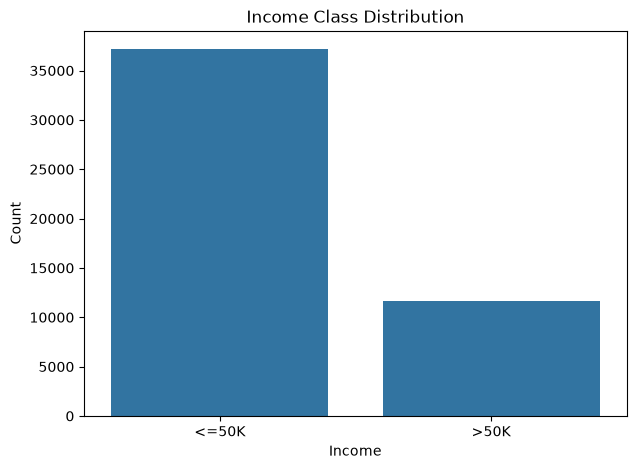

In [5]:
print("Income distribution:")
print(df["income"].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="income")
plt.title("Income Class Distribution")
plt.xlabel("Income")
plt.ylabel("Count")
plt.show()

In [6]:
# Remove target column from input features
X = df.drop("income", axis=1)

# Target variable
y = df["income"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (48842, 14)
Target shape: (48842,)

Target distribution:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (39073, 14)
Testing data: (9769, 14)
Training target: (39073,)
Testing target: (9769,)


In [8]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Categorical features:
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


C:\Users\Administrator\AppData\Local\Temp\ipykernel_6120\1124402278.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical pipeline created successfully!")

Numerical pipeline created successfully!


In [10]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical pipeline created successfully!")

Categorical pipeline created successfully!


In [11]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("ColumnTransformer created successfully!")

ColumnTransformer created successfully!


In [12]:
from sklearn.linear_model import LogisticRegression

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Complete Machine Learning Pipeline created!")

Complete Machine Learning Pipeline created!


In [13]:
model_pipeline.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [14]:
y_pred = model_pipeline.predict(X_test)

print("Predictions generated successfully!")

print("\nActual values:")
print(y_test.head(10).values)

print("\nPredicted values:")
print(y_pred[:10])

Predictions generated successfully!

Actual values:
<ArrowStringArray>
['<=50K', '<=50K', '<=50K', '<=50K',  '>50K', '<=50K',  '>50K', '<=50K',
  '>50K', '<=50K']
Length: 10, dtype: str

Predicted values:
['<=50K' '<=50K' '<=50K' '<=50K' '>50K' '<=50K' '>50K' '<=50K' '<=50K'
 '<=50K']


In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, pos_label=">50K"
))

print("Recall:", recall_score(
    y_test, y_pred, pos_label=">50K"
))

print("F1 Score:", f1_score(
    y_test, y_pred, pos_label=">50K"
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8506500153546934
Precision: 0.731437598736177
Recall: 0.5940975192472199
F1 Score: 0.6556525843757376

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      7431
        >50K       0.73      0.59      0.66      2338

    accuracy                           0.85      9769
   macro avg       0.81      0.76      0.78      9769
weighted avg       0.84      0.85      0.85      9769



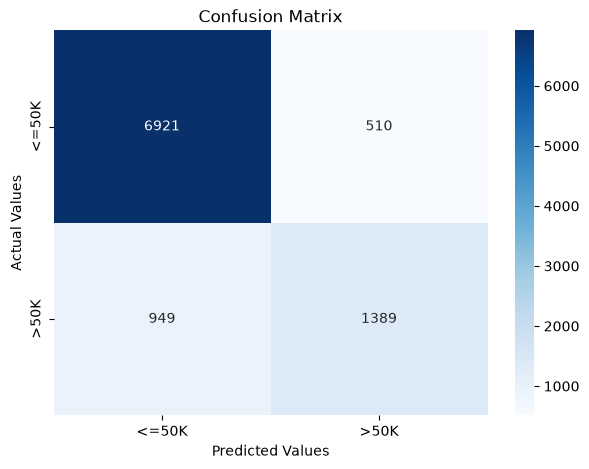

In [16]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["<=50K", ">50K"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

In [17]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, f1_score
import pandas as pd

# Define F1 scorer for the positive income class
f1_scorer = make_scorer(
    f1_score,
    pos_label=">50K"
)

# Calculate permutation importance
importance = permutation_importance(
    model_pipeline,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring=f1_scorer,
    n_jobs=1
)

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
5,marital_status,0.169906
4,education_num,0.096398
10,capital_gain,0.071051
6,occupation,0.049890
9,sex,0.022339
12,hours_per_week,0.019817
7,relationship,0.019576
0,age,0.013044
11,capital_loss,0.012536
1,workclass,0.004360


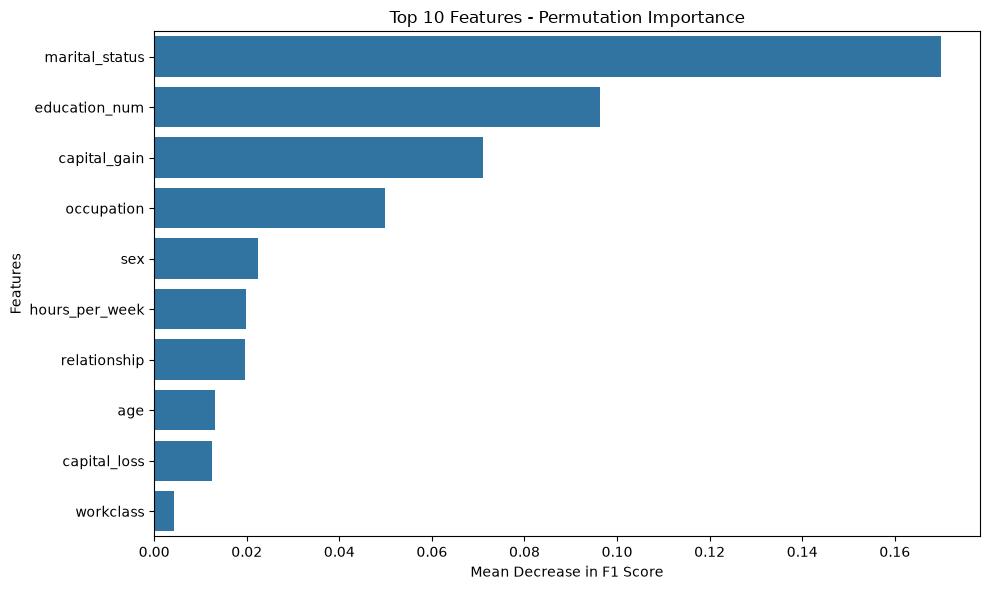

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features - Permutation Importance")
plt.xlabel("Mean Decrease in F1 Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

## Observations

1. The Adult Income dataset contains both numerical and categorical features.
2. Missing values were handled using SimpleImputer.
3. Numerical features were scaled using StandardScaler.
4. Categorical features were encoded using OneHotEncoder.
5. ColumnTransformer was used to apply different preprocessing techniques to different feature types.
6. A reusable Scikit-learn Pipeline was created using Logistic Regression.
7. The model was evaluated using accuracy, precision, recall, F1-score and a confusion matrix.
8. Permutation importance was used to identify influential input features.

## Conclusion

The experiment successfully demonstrates feature engineering and preprocessing using Scikit-learn. A reusable machine learning pipeline was developed using Pipeline and ColumnTransformer. The dataset was divided into training and testing sets before fitting transformations, helping prevent data leakage. Model performance was evaluated, and feature importance was analysed using permutation importance.

**Note:** This is an educational experiment. The Adult Income dataset contains sensitive demographic attributes, and model results should not be used for real-world consequential decisions without appropriate fairness and privacy evaluation.
